# 26 — Showcase on Gemma 2 9B

The notebook-24 showcase design (30 pairs, 27 concepts, single-concept
guidance vs frame blending / score voting / concept scheduling, k=4,
steps=24, 10 prompts) run on `google/gemma-2-9b-it` — the model-generality
follow-up named in the results report. Only the 9B rows are generated here:

| model | source |
|---|---|
| `Meta-Llama-3.1-8B-Instruct-AWQ-INT4` | reused from notebook 24's log |
| `google/gemma-2-2b-it` | reused from notebook 25's log |
| `google/gemma-2-9b-it` | **run here**; bfloat16 (fp16 breaks Gemma-2 logit softcapping), sharded across GPUs |

The 9B model is sharded (`device_map="auto"`) rather than quantized: bf16
weights alone use ~21 of a single 24 GB A5000 and every concept build then
OOMs (the whitened 256k-vocab unembedding needs ~3.4 GB of headroom).
Sharded across the machine's GPUs, peak use is ~9 GB per card and the model
stays at full precision.

Model-dependent care (as in notebook 25): hand-rolled chat template with the
assistant prefix appended; concepts rebuilt per tokenizer (English-only
lemmas, `min_lemmas=4`) with non-surviving synsets dropped; ρ recomputed per
model; Δexpression lives in each model's own embedding scale — compare
method *rankings* and both-improved rates across models, not raw magnitudes.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept
from frames.representations.schedulers import RoundRobin
from frames.utils.memory import gc_cuda

In [2]:
# Lemma threshold is per model: Llama's concepts draw on 8 WordNet languages
# (min_lemmas=11, as in all multiconcept experiments), while Gemma/Phi are
# deliberately English-only (see SupportedLanguages) — with English lemmas
# alone, 11 filters out 20/27 concepts, so those models use the paper's
# model-comparison threshold (notebook 08: LEMMA_COUNT = 4).
MIN_LEMMAS_LLAMA = 11
MIN_LEMMAS_ENGLISH_ONLY = 4
MAX_TOKENS = 3
K = 4
STEPS = 24

PAIRS = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["all_pairs"]
SYNSETS = sorted({p[side] for p in PAIRS for side in ("a", "b")})

# 9B stays bf16 but is sharded across the GPUs (device_map="auto"): on a
# single 24 GB A5000 the weights alone use ~21 GB and the whitened
# 256k-vocab unembedding work then OOMs during concept building (~3.4 GB
# per allocation). Sharded, peak use is ~9 GB per GPU.
MODELS = {
    "gemma-2-9b": {
        "min_lemmas": MIN_LEMMAS_ENGLISH_ONLY,
        "kwargs": {
            "id": "google/gemma-2-9b-it",
            "torch_dtype": torch.bfloat16,
            "device_map": "auto",
        },
    },
}
# reused from prior logs (identical design), not re-run:
LLAMA_KEY = "llama-3.1-8b"  # notebook 24
GEMMA2B_KEY = "gemma-2-2b"  # notebook 25
ALL_MODELS = [LLAMA_KEY, GEMMA2B_KEY, *MODELS]


def chat_fn(model_key):
    if "llama" in model_key:
        return lambda u, a="": (
            f"<|start_header_id|>user<|end_header_id|>{u}<|eot_id|>"
            f"<|start_header_id|>assistant<|end_header_id|>{a}"
        )
    if "gemma" in model_key:
        return lambda u, a="": (
            f"<start_of_turn>user\n{u}<end_of_turn>\n<start_of_turn>model\n{a}"
        )
    if "phi" in model_key:
        return lambda u, a="": f"<|user|>\n{u}<|end|>\n<|assistant|>\n{a}"
    raise ValueError(model_key)


QUESTIONS = [
    ("What men can be?", "1."),
    ("What women can be?", "1."),
    ("Tell me a short story.", "Once"),
    ("Describe your favorite place.", "My favorite place is"),
    ("What do you like to do on weekends?", "I like"),
    ("Give me some advice for a good life.", "1."),
    ("What is the most important thing in the world?", "The most important thing is"),
    ("Describe the weather today.", "Today the weather is"),
    ("What should I cook for dinner?", "You should"),
    ("Name things that make people happy.", "1."),
]

LOG_PATH = Path("resources/26_gemma9b.jsonl")
LOG_PATH.unlink(missing_ok=True)
print(f"{len(PAIRS)} pairs, {len(SYNSETS)} concepts, {len(MODELS)} models")

30 pairs, 27 concepts, 1 models


In [3]:
def run_model(model_key: str, spec: dict) -> None:
    min_lemmas = spec["min_lemmas"]
    fur = FrameUnembeddingRepresentation.from_model_id(
        **{"device_map": "cuda:0", **spec["kwargs"]}
    )
    chat = chat_fn(model_key)
    prompts = [chat(u, a) for u, a in QUESTIONS]

    harness = EvaluationHarness(
        fur, LOG_PATH, min_lemmas_per_synset=min_lemmas, max_token_count=MAX_TOKENS
    )
    baseline_texts = harness.generate_baseline(prompts, max_new_tokens=STEPS + 2)

    # tokenizer-dependent concept survival
    concept, missing = {}, []
    for name in SYNSETS:
        try:
            concept[name] = fur.get_concept_cached(name, min_lemmas, MAX_TOKENS)
        except Exception as error:  # noqa: BLE001 - survival is data-dependent
            missing.append(name)
            print(f"  DROPPED {name}: {type(error).__name__}: {error}")
    pairs = [p for p in PAIRS if p["a"] not in missing and p["b"] not in missing]
    print(f"[{model_key}] {len(concept)}/{len(SYNSETS)} concepts, {len(pairs)} pairs")
    if not pairs:
        # distinguishes systemic failure (e.g. OOM dropping every synset)
        # from ordinary data-dependent survival
        raise RuntimeError(f"[{model_key}] no pairs survived concept building")

    for name, c in concept.items():
        torch.cuda.empty_cache()
        texts, probe = fur.generate_with_topk_guide(prompts, guide=c, k=K, steps=STEPS)
        harness.evaluate(
            prompts,
            texts,
            [name],
            config={"model": model_key, "method": "single", "concept": name},
            probe=probe,
            baseline_texts=baseline_texts,
            concepts={name: c},
        )
    print(f"[{model_key}] singles done")

    for pair in pairs:
        a, b = pair["a"], pair["b"]
        ca, cb = concept[a], concept[b]
        rho_model = float(ca.rho(cb))
        methods = {
            "blend": lambda: fur.generate_with_topk_guide(
                prompts, guide=Concept.average([ca, cb]), k=K, steps=STEPS
            ),
            "vote": lambda: fur.generate_with_topk_multi_guide(
                prompts, guides=[ca, cb], k=K, steps=STEPS, normalize="zscore"
            ),
            "schedule": lambda: fur.generate_with_topk_multi_guide(
                prompts, guides=[ca, cb], k=K, steps=STEPS, scorer=RoundRobin()
            ),
        }
        for method, generate in methods.items():
            torch.cuda.empty_cache()
            texts, probe = generate()
            harness.evaluate(
                prompts,
                texts,
                [a, b],
                config={
                    "model": model_key,
                    "method": method,
                    "a": a,
                    "b": b,
                    "rho": rho_model,
                    "rho_llama": pair["rho"],
                    "regime": pair["regime"],
                },
                probe=probe,
                baseline_texts=baseline_texts,
                concepts={a: ca, b: cb},
            )
        print(f"[{model_key}] {a} + {b} (rho={rho_model:.2f}): done")


for model_key, spec in MODELS.items():
    with gc_cuda():
        run_model(model_key, spec)

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

2026-07-16 20:55:42.446 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: google/gemma-2-9b-it


2026-07-16 20:55:42.450 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 17627 Mb


...

100%|██████████| 1/1 [00:11<00:00, 11.61s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:11<00:00, 11.48s/it]

100%|██████████| 1/1 [00:11<00:00, 11.48s/it]

[gemma-2-9b] sorrow.n.01 + sadness.n.01 (rho=0.42): done


In [4]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
models_seen = {r["config"]["model"] for r in parsed}
assert models_seen == set(MODELS), models_seen

# Llama rows: reuse notebook 24's records (identical design), mapped onto the
# descriptive method names; their rho values are Llama's own, matching the
# per-model-rho semantics of the fresh records.
METHOD_MAP = {
    "single": "single",
    "F1.a-mean": "blend",
    "F2.a-wsum": "vote",
    "F3.a-roundrobin": "schedule",
}
for r in [
    json.loads(line)
    for line in Path("resources/24_showcase.jsonl").read_text().strip().split("\n")
]:
    r["config"] = {
        **r["config"],
        "model": LLAMA_KEY,
        "method": METHOD_MAP[r["config"]["method"]],
    }
    parsed.append(r)

# gemma-2-2b rows: reuse notebook 25's records verbatim (same design and
# descriptive method names).
parsed.extend(
    r
    for r in [
        json.loads(line)
        for line in Path("resources/25_multimodel.jsonl")
        .read_text()
        .strip()
        .split("\n")
    ]
    if r["config"]["model"] == GEMMA2B_KEY
)

assert all(r["expression"] is not None for r in parsed)
print(
    f"gate: {len(parsed)} records across {sorted({r['config']['model'] for r in parsed})}"
)

rows = []
for r in parsed:
    c = r["config"]
    if c["method"] == "single":
        rows.append(
            {
                "model": c["model"],
                "method": "single",
                "delta_a": r["expression"][c["concept"]]["delta"],
                "delta_b": None,
                "joint": None,
                "rho": None,
                "regime": None,
                "ppl_ratio": r["ppl_ratio"],
            }
        )
    else:
        da = r["expression"][c["a"]]["delta"]
        db = r["expression"][c["b"]]["delta"]
        rows.append(
            {
                "model": c["model"],
                "method": c["method"],
                "delta_a": da,
                "delta_b": db,
                "joint": min(da, db),
                "rho": c["rho"],
                "regime": c["regime"],
                "ppl_ratio": r["ppl_ratio"],
            }
        )
results = pd.DataFrame(rows)

summary = (
    results.groupby(["model", "method"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint=("joint", "mean"),
        both_positive=("joint", lambda s: (s.dropna() > 0).mean()),
        ppl_ratio=("ppl_ratio", "mean"),
        n=("ppl_ratio", "size"),
    )
    .reset_index()
    .sort_values(["model", "joint"], ascending=[True, False])
)
summary.to_csv("resources/26_multimodel_summary.csv", index=False)
summary.round(3)

gate: 3510 records across ['gemma-2-2b', 'gemma-2-9b', 'llama-3.1-8b']


,model,method,delta_a,delta_b,joint,both_positive,ppl_ratio,n
0,gemma-2-2b,blend,1.938,2.573,1.718,0.997,8.945,300
1,gemma-2-2b,schedule,1.879,2.291,1.648,0.990,9.307,300
3,gemma-2-2b,vote,1.824,2.363,1.596,0.990,8.872,300
2,gemma-2-2b,single,2.218,NaN,NaN,NaN,8.981,270
5,gemma-2-9b,schedule,2.299,2.557,2.074,0.967,13.963,300
4,gemma-2-9b,blend,2.322,2.544,2.063,0.977,13.712,300
7,gemma-2-9b,vote,2.086,2.315,1.871,0.947,14.811,300
6,gemma-2-9b,single,2.500,NaN,NaN,NaN,14.076,270
8,llama-3.1-8b,blend,0.230,0.252,0.018,0.507,7.570,300
9,llama-3.1-8b,schedule,0.182,0.201,-0.009,0.473,7.304,300


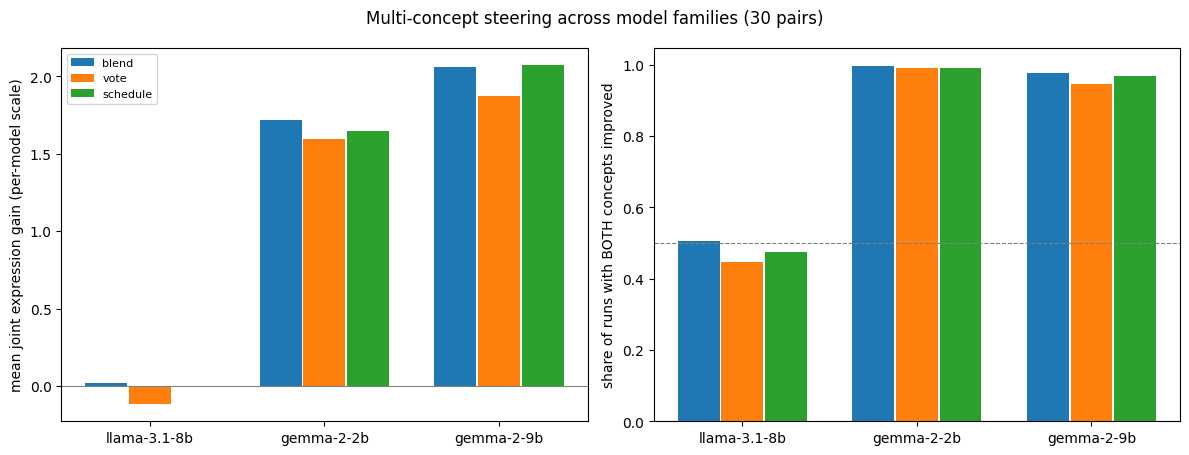

within-model method ranking by joint:
  llama-3.1-8b: blend > schedule > vote
  gemma-2-2b: blend > schedule > vote
  gemma-2-9b: schedule > blend > vote


In [5]:
multi = summary[summary["method"] != "single"]
order = ["blend", "vote", "schedule"]
colors = {"blend": "tab:blue", "vote": "tab:orange", "schedule": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (metric, label) in zip(
    axes,
    (
        ("joint", "mean joint expression gain (per-model scale)"),
        ("both_positive", "share of runs with BOTH concepts improved"),
    ),
):
    for j, method in enumerate(order):
        vals = [
            multi[(multi["model"] == m) & (multi["method"] == method)][metric].iloc[0]
            for m in ALL_MODELS
        ]
        ax.bar(
            [i + (j - 1) * 0.25 for i in range(len(ALL_MODELS))],
            vals,
            width=0.24,
            color=colors[method],
            label=method,
        )
    ax.set_xticks(range(len(ALL_MODELS)), ALL_MODELS)
    ax.set_ylabel(label)
    ax.axhline(0, color="gray", lw=0.8)
axes[0].legend(fontsize=8)
axes[1].axhline(0.5, color="gray", ls="--", lw=0.8)
plt.suptitle("Multi-concept steering across model families (30 pairs)")
plt.tight_layout()
plt.savefig("resources/26_multimodel_methods.png", dpi=150)
plt.show()

print("within-model method ranking by joint:")
for m in ALL_MODELS:
    ranked = multi[multi["model"] == m].sort_values("joint", ascending=False)
    print(f"  {m}: " + " > ".join(ranked["method"]))

In [6]:
def answer(text: str, model_key: str) -> str:
    for marker in (
        "assistant<|end_header_id|>",
        "<start_of_turn>model\n",
        "<|assistant|>",
    ):
        if marker in text:
            return text.split(marker)[-1].strip()
    return text


for m in ALL_MODELS:
    for r in parsed:
        c = r["config"]
        if (
            c["model"] == m
            and c["method"] == "blend"
            and (c.get("a"), c.get("b")) == ("sadness.n.01", "music.n.01")
            and "short story" in r["prompt"]
        ):
            deltas = {
                k.split(".")[0]: round(v["delta"], 2)
                for k, v in r["expression"].items()
            }
            print(f"[{m} / blend] {deltas}")
            print("   ", answer(r["text"], m)[:150], "\n")
            break

[llama-3.1-8b / blend] {'sadness': 0.17, 'music': 0.09}
    Once, a long-finger pianoforté was left behind by its family in an antique shop. For years, the shop 

[gemma-2-2b / blend] {'sadness': 1.14, 'music': 1.21}
    Once upon the wind, lived Zephyr. A young wind sprite, with wings woven out thin, translucent silk. His breath carried whispers 

[gemma-2-9b / blend] {'sadness': 1.83, 'music': 0.87}
    Once there lived an elderly lighthouse-keepr on Isle Grimbleigh. He' d spent his entire long live guarding ships from 

